# 01 - Data exploration

This shared notebook is the starting point for the intermediate delivery. It audits the supplied files before the group chooses preprocessing or modelling decisions. Run all cells in JupyterLab from the repository root or the notebooks directory.

**Question:** Can we predict whether a customer will make another purchase within 90 days of the current purchase?

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
TARGET = 'repeat_purchase_90d'
DATA_DIR = Path('data')
if not DATA_DIR.is_dir():
    DATA_DIR = Path('..') / 'data'
if not DATA_DIR.is_dir():
    raise FileNotFoundError('Open this notebook from the repository root or the notebooks directory.')

In [5]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
clientes = pd.read_csv(DATA_DIR / 'clientes.csv')
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')

print(f'Train: {train.shape[0]:,} rows x {train.shape[1]} columns')
print(f'Test: {test.shape[0]:,} rows x {test.shape[1]} columns')
print(f'Clientes: {clientes.shape[0]:,} rows x {clientes.shape[1]} columns')
print(f'Sample submission: {sample_submission.shape[0]:,} rows x {sample_submission.shape[1]} columns')

Train: 6,534 rows x 39 columns
Test: 986 rows x 38 columns
Clientes: 1,143 rows x 13 columns
Sample submission: 986 rows x 2 columns


## 1. First look

Each row of `train` and `test` is a purchase occasion. `train` additionally contains the known binary target. `clientes` has one customer-level row per `customer_id` and is optional extra information; do not merge it until we inspect its quality and test whether it improves validation performance.

In [6]:
print("TRAIN:")
display(train.head())
print(" ")

print("TEST:")
display(test.head())
print(" ")

print("CLIENTES:")
display(clientes.head())
print(" ")

print("SAMPLE SUBMISSION")
display(sample_submission.head())
print(" ")

TRAIN:


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


 
TEST:


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,286.37,582.05,232.82,53.55,0.0,0.0,349.23,104.409267,22,1,40.0,3905,122,46287.23,379.403525,528.297548,2.72,3198.00,31.942149,48.035282,0,0.0,6,1295.82,9,2498.90,23,9140.12,519184,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 80,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000006,0.621602
1,1949.25,1725.00,1725.00,224.25,0.0,0.0,0.00,0.000000,1,1,63.0,3613,58,243340.48,4195.525517,2545.945318,569.52,11031.74,62.280702,46.416113,0,0.0,1,3137.11,2,5086.36,4,16252.35,942149,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 2,2025-07-26,10000008,-1.318874
2,2738.71,4114.83,2738.71,0.00,0.0,0.0,1376.12,1019.466586,99,1,230.0,1786,16,21570.23,1348.139375,1096.651106,40.09,3363.23,103.733333,78.583410,0,0.0,0,0.00,0,0.00,4,4570.76,386654,Maybe Tomorrow Payment 4,VLOOKUP Master 1,Decorative Dashboard Zone 2,Maybe Tomorrow Delivery 54,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000010,1.251905
3,726.98,591.04,591.04,135.94,0.0,0.0,0.00,341.649008,39,2,234.0,374,3,3907.61,1302.536667,881.237007,296.37,1937.15,70.000000,67.882251,0,0.0,0,0.00,0,0.00,2,1970.46,588088,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 35,Final Excel Warehouse 1,Ctrl Z Series 2,2025-11-05,10000020,0.988362
4,670.76,555.49,545.33,125.43,0.0,0.0,10.16,326.715748,13,1,NaN,386,5,4877.08,975.416000,334.407265,546.28,1305.09,77.000000,43.825411,0,0.0,1,759.06,2,2062.37,4,4330.80,610152,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 1,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 2,2026-07-12,10000025,0.511535


 
CLIENTES:


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


 
SAMPLE SUBMISSION


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1


Target counts:


,count
repeat_purchase_90d,
1,3654
0,2880


Target proportions:


,proportion
repeat_purchase_90d,
1,0.559229
0,0.440771


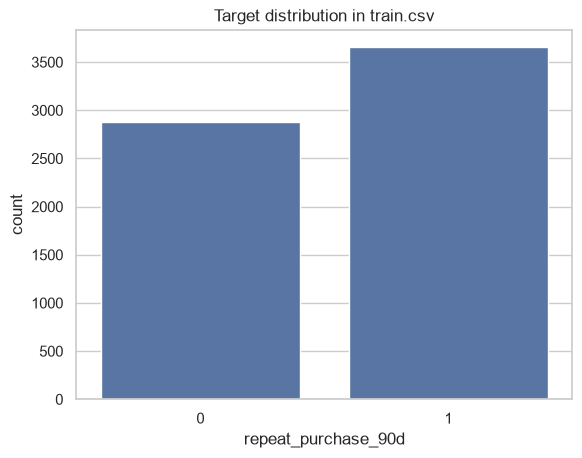

In [7]:
print('Target counts:')
display(train[TARGET].value_counts().rename_axis(TARGET).to_frame('count'))

print('Target proportions:')
display(train[TARGET].value_counts(normalize=True).rename_axis(TARGET).to_frame('proportion'))

ax = sns.countplot(data=train, x=TARGET)
ax.set_title('Target distribution in train.csv')
plt.show()

**Conclusion:** The proportion is equilibrated!

## 2. Structure and data quality

In this section, we inspect the structure of the training dataset, descriptive statistics, missing values, and duplicated data. At this stage, we only inspect the data and do not make any changes.

### Structure of training dataset
Show the number of rows, the columns, the number of non-missing values, and the data type of each column. 

In [8]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 non-null

Since the training dataset contains 6,534 observations, every column with a non-null count below 6,534 contains missing values. We conclude that all columns contain missing values except `repeat_purchase_90d`, `customer_id`, and `ID`, which are complete.

Most incomplete columns have 65 missing values. However, some historical variables have considerably more missing values, particularly `prior_std_gap_days`, `prior_mean_gap_days`, and `prior_std_purchase_value`. Only `repeat_purchase_90d`, `customer_id`, and `ID` have no missing values.

In [12]:
descriptive_statistics = train.describe(include='all').T  # describe mistura colunas numericas com colunas de texto, daí termos tantos Nans 
descriptive_statistics


#unique: quantos valores diferentes existem na coluna -> ajuda a perceber quantas categorias existem numa variável, se uma coluna tem poucas categorias, como 3 metodos de pagamento, se tem demasiadas, se tiver Nan é porque a estatisitica não é aplicavel na coluna.  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,NaN,NaN,NaN,925.556262,1334.997733,0.93,188.92,476.74,1087.67,22297.21
Total Bruto,6469.0,NaN,NaN,NaN,886.152705,1327.641086,0.83,175.74,445.74,1036.7,21578.28
Total Liquido,6469.0,NaN,NaN,NaN,773.336384,1136.355723,0.76,154.38,389.91,903.37,18127.81
Total Imp_,6469.0,NaN,NaN,NaN,152.219878,225.262375,0.0,29.93,79.74,184.84,4169.4
Total Portes,6469.0,NaN,NaN,NaN,1.151427,5.844091,0.0,0.0,0.0,0.0,181.06
Total Desc_ Global,6469.0,NaN,NaN,NaN,0.349907,5.116564,0.0,0.0,0.0,0.0,218.49
Total Desc_ Linha,6469.0,NaN,NaN,NaN,112.466414,289.986307,0.0,0.0,13.13,92.28,4103.44
Custo,6469.0,NaN,NaN,NaN,328.16504,519.507218,0.0,49.05,152.54,396.061499,7427.400583
N_ Detalhes,6469.0,NaN,NaN,NaN,21.524501,27.713419,1.0,4.0,11.0,29.0,423.0
invoice_count_current_purchase,6469.0,NaN,NaN,NaN,1.066007,0.310807,1.0,1.0,1.0,1.0,5.0


The descriptive statistics reveal several potential data-quality issues. The minimum values of `days_since_previous_purchase` and `prior_mean_gap_days` are negative, which appears implausible for time intervals. `prior_mean_purchase_value` and `spend_365d` contain extremely large values, including a maximum of 1,000,000,000, and also contain negative monetary values. These observations should be investigated before modelling.

At least 75% of the observations have no shipping costs or global discount. Most purchase occasions contain only one invoice. Some categorical variables are strongly dominated by one category, particularly `commercial_zone` and `warehouse`, while `transport_method` contains 80 different categories. In addition, `purchase_date` is currently stored as text and should later be converted to a date format.

### Missing Values

We count the number of missing values in each column. This allows us to identify which variables are incomplete and how many observations are missing.

In [13]:
missing_values = train.isna().sum()
missing_values

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
repeat_purchase_90d                  0
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                           65
purchase_count_180d      

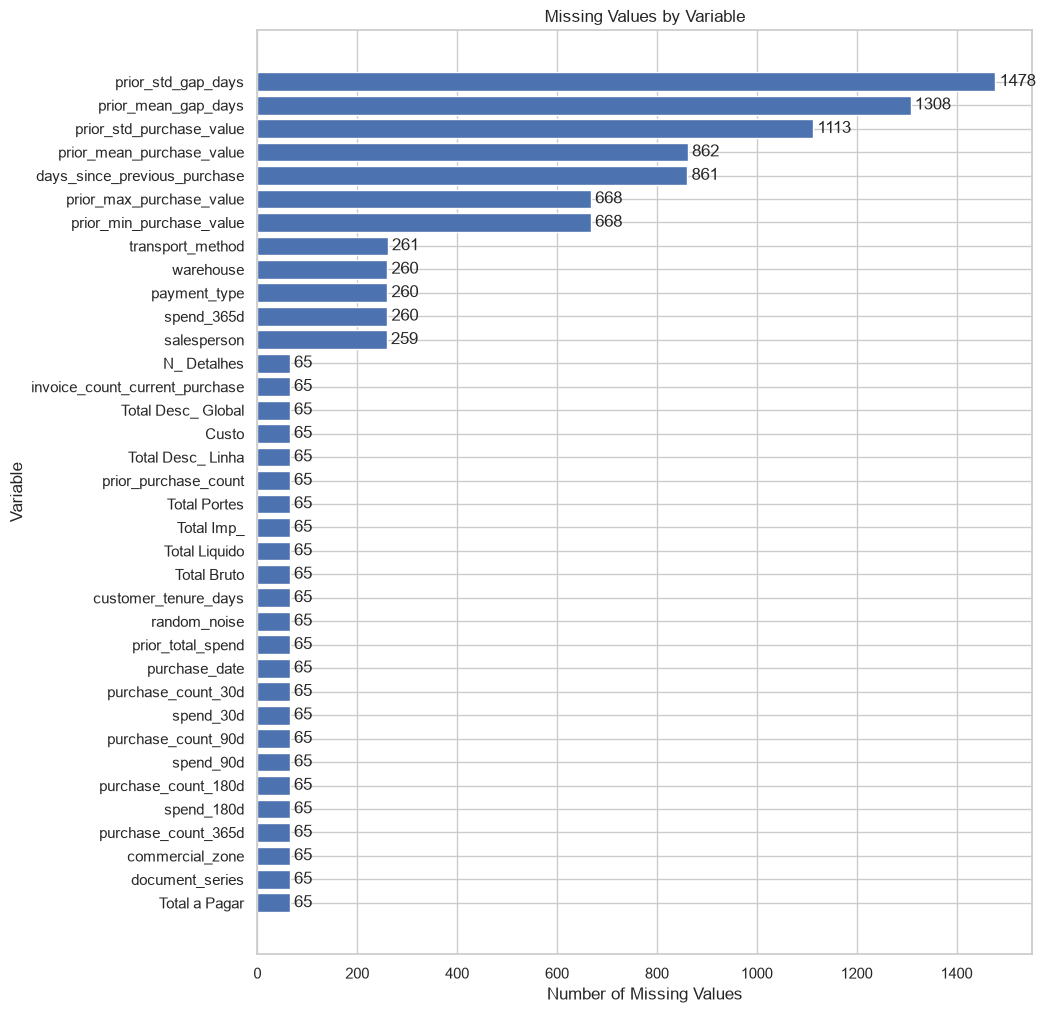

In [14]:
missing_variables = missing_values[missing_values > 0]
missing_variables = missing_variables.sort_values()

plt.figure(figsize=(10, 12))

bars = plt.barh(
    missing_variables.index,
    missing_variables.values
)

plt.bar_label(bars, padding=3)

plt.title('Missing Values by Variable')
plt.xlabel('Number of Missing Values')
plt.ylabel('Variable')

plt.show()

The chart shows that missing values are particularly frequent in variables related to the customers' previous purchasing history. `prior_std_gap_days` has the highest number of missing values, followed by `prior_mean_gap_days` and `prior_std_purchase_value`.

Several other variables have only 65 missing values, suggesting that the same observations may be incomplete across multiple variables. This possibility should be investigated before deciding how to handle the missing data.

### Percentage of Missing Values

We calculate the percentage of missing values in each incomplete variable. Percentages make it easier to understand the importance of the missing data relative to the total number of observations.

In [17]:
missing_percentage = missing_variables / len(train) * 100
missing_percentage

Total a Pagar                      0.994796
document_series                    0.994796
commercial_zone                    0.994796
purchase_count_365d                0.994796
spend_180d                         0.994796
purchase_count_180d                0.994796
spend_90d                          0.994796
purchase_count_90d                 0.994796
spend_30d                          0.994796
purchase_count_30d                 0.994796
purchase_date                      0.994796
prior_total_spend                  0.994796
random_noise                       0.994796
customer_tenure_days               0.994796
Total Bruto                        0.994796
Total Liquido                      0.994796
Total Imp_                         0.994796
Total Portes                       0.994796
prior_purchase_count               0.994796
Total Desc_ Linha                  0.994796
Custo                              0.994796
Total Desc_ Global                 0.994796
invoice_count_current_purchase  

`prior_std_gap_days` has the highest percentage of missing values, with approximately 22.6%, followed by `prior_mean_gap_days` with approximately 20.0% and `prior_std_purchase_value` with approximately 17.0%.

The variables with 65 missing observations have approximately 1.0% missing data.

### Duplicated Data

We check whether the training dataset contains completely duplicated rows. Duplicated observations could incorrectly give more importance to repeated data during model training.

We also check whether `customer_id` is duplicated in the `clientes` dataset, which is expected to contain one row per customer.

In [21]:
duplicated_rows = train.duplicated().sum()
duplicated_customers = clientes['customer_id'].duplicated().sum()

print("Duplicated rows in train:", duplicated_rows)
print("Duplicated customer IDs in clientes:", duplicated_customers)

Duplicated rows in train: 0
Duplicated customer IDs in clientes: 0


The training dataset does not contain completely duplicated rows. The `clientes` dataset also does not contain duplicated customer identifiers, meaning that each row represents a different customer.

## 3. Initial feature roles

`ID` is the row identifier for Kaggle and must not be used as a predictor. `customer_id` is a join key and potentially identifier-like, so it requires an explicit experiment and justification before use. `purchase_date` must be converted to a date before making any time-based features or validation split.

In [ ]:
id_columns = ['ID', 'customer_id']
date_columns = ['purchase_date']

numeric_columns = train.select_dtypes(include='number').columns.drop(TARGET).tolist()
categorical_columns = [
    column for column in train.select_dtypes(include=['object', 'category']).columns
    if column not in id_columns + date_columns
]

print('Numeric predictors:', numeric_columns)
print('Categorical predictors:', categorical_columns)
print('Potential identifier/date columns:', id_columns + date_columns)

dates = pd.to_datetime(train['purchase_date'], errors='coerce')
print(f'Purchase-date range: {dates.min().date()} to {dates.max().date()}')
print(f'Invalid or missing purchase dates: {dates.isna().sum()}')

## Next decisions

Before building the first model, agree on a validation split that reflects the fact that `test.csv` contains later purchases. The next notebook should build a **minimal baseline pipeline**: numerical median imputation, categorical missing level plus one-hot encoding, no use of `ID`, and a Dummy Classifier plus two real models. Then test one change at a time against that baseline.